## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

The point of estimating the ATE is to find the difference in percentages between the two groups. In this case, we want to find the difference in survival rates between receiving the pump and not receiving it. Based on the current results, I would say there is approximately a 1 percentage point higher survival rate for patients who did not receive the pump. Even though it's only a 1 percentage difference, I think it's still worth considering, so I would prefer not receiving the pump.

In [2]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [3]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

They are similar in terms of shape, although we can see some differences in their positions. Looking at the KDE, we can see that the conservative group (no pump) is slightly more to the right, meaning this group tends to have a slightly higher survival rate, since the estimates are concentrated more to the right. Looking at the ECDF, we notice that the invasive group (pump) is higher than the conservative group at the same survival rate, meaning a larger proportion of its bootstrap estimates are below or equal to that survival rate. This suggests that the pump group tends to have lower survival rates compared to the conservative group.

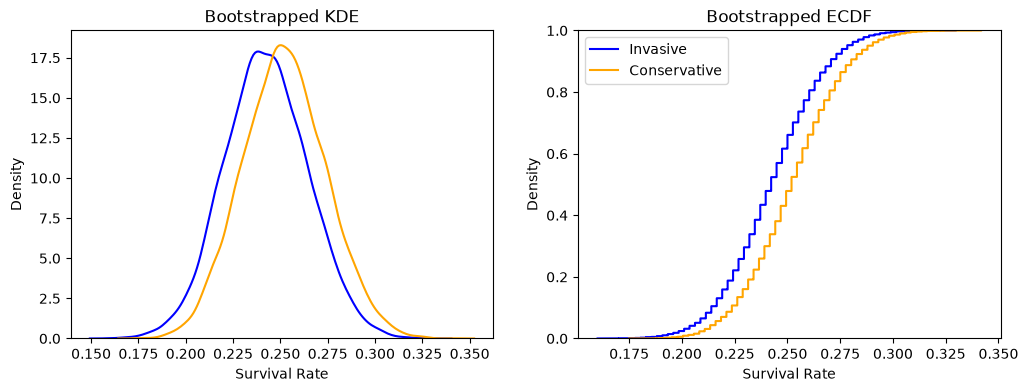

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

Yes, it has roughly a bell shape, and looking at the KDE and ECDF, we can see that the bootstrapped ATE values range approximately from -0.10 to 0.10, with most of the values concentrated around -0.01.

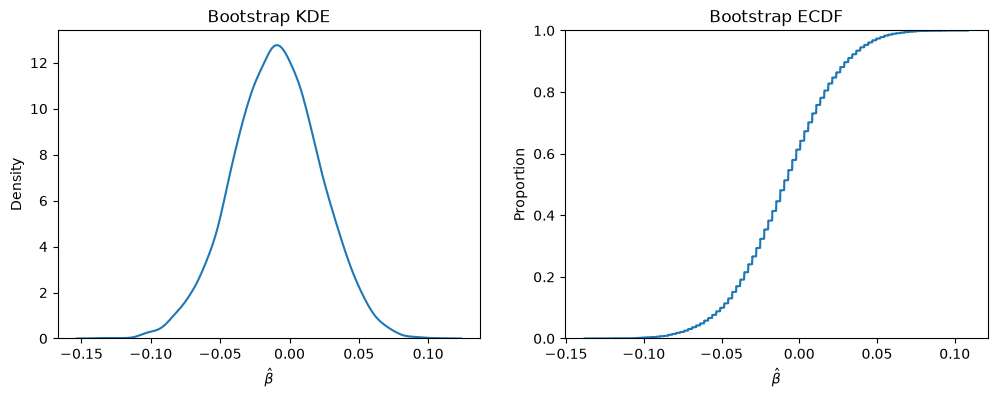

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

Zero is in all three confidence intervals, and for that reason, we fail to reject the null hypothesis for all of them. This means we don't have enough evidence to conclude that the treatment has an effect on survival.

In [6]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06117357  0.04182678]
95% CI: [-0.07395383  0.05208985]
99% CI: [-0.09204827  0.07010452]


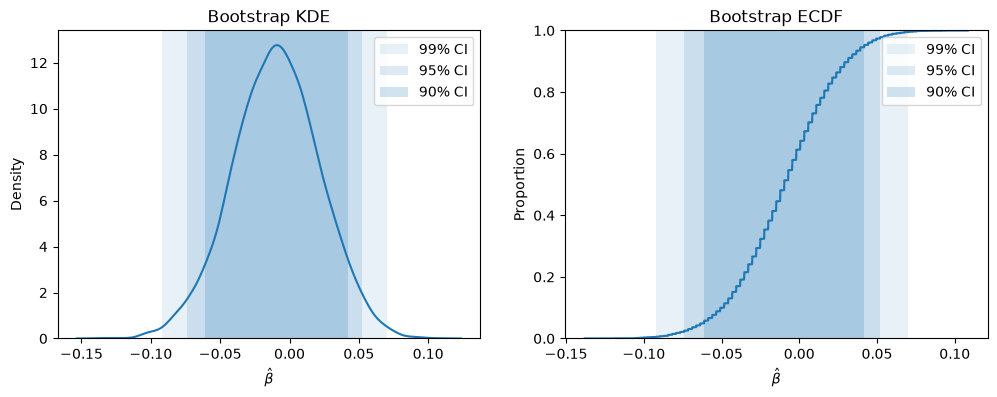

In [7]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?

We learned that patients have a slightly higher probability of survival when they don't receive the balloon pump. However, even though the results show a small difference in percentage, we don't have enough evidence to conclude that the treatment has an effect on survival. This means the difference we observed could simply be due to random sampling variation rather than an actual effect of the treatment.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 

In [11]:
df = pd.read_csv('./data/diabetes.csv')

print(df.columns)
df.head()

Index(['Unnamed: 0', 'treatment', 'outcome'], dtype='object')


,Unnamed: 0,treatment,outcome
0,1,met,success
1,2,rosi,failure
2,3,rosi,success
3,4,lifestyle,success
4,5,met,success


In [15]:
print(pd.crosstab(df['treatment'], df['outcome']), '\n')

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 



In [16]:
df['success'] = (df['outcome'] == 'success').astype(int)

print('Average outcomes:')
print(df.groupby('treatment')['success'].mean())

Average outcomes:
treatment
lifestyle    0.534188
met          0.482759
rosi         0.613734
Name: success, dtype: float64


2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 

In [17]:
R = 10_000

df_met = df.loc[df['treatment'] == 'met', :]
df_rosi = df.loc[df['treatment'] == 'rosi', :]
df_lifestyle = df.loc[df['treatment'] == 'lifestyle', :]

outcome_met = []
outcome_rosi = []
outcome_lifestyle = []

for t in range(R):
    df_met_t = df_met.sample(frac=1.0, replace=True)
    df_rosi_t = df_rosi.sample(frac=1.0, replace=True)
    df_lifestyle_t = df_lifestyle.sample(frac=1.0, replace=True)

    met_t = df_met_t['success'].mean()
    rosi_t = df_rosi_t['success'].mean()
    lifestyle_t = df_lifestyle_t['success'].mean()

    outcome_met.append(met_t)
    outcome_rosi.append(rosi_t)
    outcome_lifestyle.append(lifestyle_t)

3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.

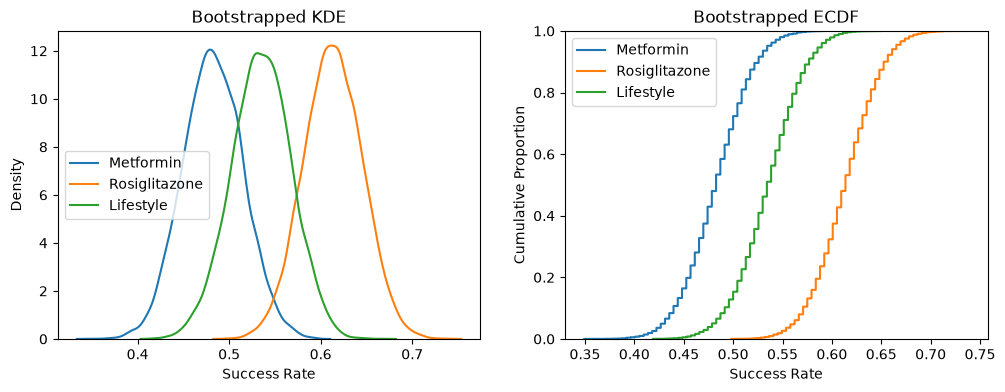

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_met, label='Metformin', ax=ax[0])
sns.kdeplot(outcome_rosi, label='Rosiglitazone', ax=ax[0])
sns.kdeplot(outcome_lifestyle, label='Lifestyle', ax=ax[0])

ax[0].set(title='Bootstrapped KDE',
          xlabel='Success Rate', ylabel='Density')
ax[0].legend()

sns.ecdfplot(outcome_met, label='Metformin', ax=ax[1])
sns.ecdfplot(outcome_rosi, label='Rosiglitazone', ax=ax[1])
sns.ecdfplot(outcome_lifestyle, label='Lifestyle', ax=ax[1])

ax[1].set(title='Bootstrapped ECDF',
          xlabel='Success Rate', ylabel='Cumulative Proportion')
ax[1].legend()

plt.show()


The pattern I currently see is that as the success rate increases, the distributions seem to shift more to the right.

4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.

In [23]:
ate_met_rosi = np.array(outcome_met) - np.array(outcome_rosi)
ate_met_lifestyle = np.array(outcome_met) - np.array(outcome_lifestyle)
ate_rosi_lifestyle = np.array(outcome_rosi) - np.array(outcome_lifestyle)

print('ATE Met vs Rosi: ', np.round(np.mean(ate_met_rosi), 3))
print('ATE Met vs Lifestyle: ', np.round(np.mean(ate_met_lifestyle), 3))
print('ATE Rosi vs Lifestyle: ', np.round(np.mean(ate_rosi_lifestyle), 3))

ATE Met vs Rosi:  -0.131
ATE Met vs Lifestyle:  -0.053
ATE Rosi vs Lifestyle:  0.078


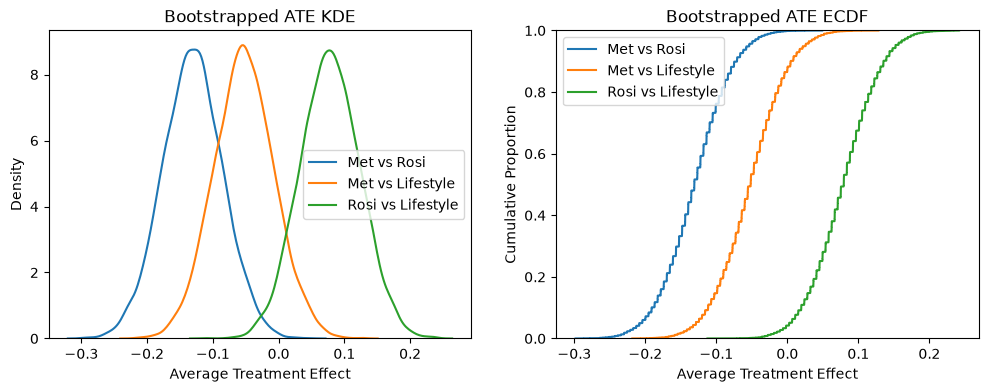

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(ate_met_rosi, label='Met vs Rosi', ax=ax[0])
sns.kdeplot(ate_met_lifestyle, label='Met vs Lifestyle', ax=ax[0])
sns.kdeplot(ate_rosi_lifestyle, label='Rosi vs Lifestyle', ax=ax[0])

ax[0].set(title='Bootstrapped ATE KDE',
          xlabel='Average Treatment Effect', ylabel='Density')
ax[0].legend()

sns.ecdfplot(ate_met_rosi, label='Met vs Rosi', ax=ax[1])
sns.ecdfplot(ate_met_lifestyle, label='Met vs Lifestyle', ax=ax[1])
sns.ecdfplot(ate_rosi_lifestyle, label='Rosi vs Lifestyle', ax=ax[1])

ax[1].set(title='Bootstrapped ATE ECDF',
          xlabel='Average Treatment Effect', ylabel='Cumulative Proportion')
ax[1].legend()

plt.show()


5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

In [22]:
# 95% CI
ci_met_rosi = np.quantile(ate_met_rosi, [0.025, 0.975])
ci_met_lifestyle = np.quantile(ate_met_lifestyle, [0.025, 0.975])
ci_rosi_lifestyle = np.quantile(ate_rosi_lifestyle, [0.025, 0.975])

print("Met vs Rosi:", ci_met_rosi)
print("Met vs Lifestyle:", ci_met_lifestyle)
print("Rosi vs Lifestyle:", ci_rosi_lifestyle)

Met vs Rosi: [-0.22134499 -0.04067957]
Met vs Lifestyle: [-0.14172561  0.0387931 ]
Rosi vs Lifestyle: [-0.01039947  0.16943619]


After looking at the results, we fail to reject the null hypothesis for Met vs. Lifestyle and Rosi vs. Lifestyle, since both confidence intervals include zero. However, we find enough evidence to reject the null hypothesis for Met vs. Rosi, since its confidence interval does not include zero. This suggests that Met and Rosi have a statistically significant difference in their success rates. Based on the results, I would say that Rosi seems to be the most effective treatment.

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

For this experiment, we compared the statistical results of three treatments: Metformin, Rosiglitazone, and Lifestyle intervention. All three treatments aim to help prevent the progression to diabetes. We were interested in measuring two things: the success rate of each treatment and whether there were statistically significant differences between them. Using the provided clinical trial data, we calculated the average success rates, performed 10,000 bootstrap resamples within each treatment group, and calculated pairwise Average Treatment Effects (ATEs) and 95% confidence intervals.

First, we calculated the success rate for each treatment. The results showed that Lifestyle had a success rate of 53.42%, Metformin had 48.28%, and Rosiglitazone had 61.37%. We then bootstrapped the outcomes to create KDE and ECDF plots. As shown in the visualizations, treatments with higher success rates tended to have distributions shifted farther to the right. These patterns support our initial observations, with Rosiglitazone having the highest estimated success rate and Metformin the lowest.

Next, we wanted to determine whether there were clear differences between the treatments, so we calculated the pairwise ATEs and their 95% bootstrap confidence intervals. We used zero as our null hypothesis, representing no difference between treatments. The confidence interval for Metformin versus Rosiglitazone was [-0.2213, -0.0407], which does not include zero. Therefore, we reject the null hypothesis and find evidence of a statistically significant difference between these treatments. However, the intervals for Metformin versus Lifestyle [-0.1417, 0.0388] and Rosiglitazone versus Lifestyle [-0.0104, 0.1694] both include zero. Therefore, we fail to reject the null hypothesis for these comparisons because there is insufficient evidence of a statistically significant difference.

Based on these findings, Rosiglitazone appears to be the most effective treatment in terms of observed success rates. The results provide statistical evidence that Rosiglitazone performs better than Metformin, suggesting that adopting Rosiglitazone over Metformin could be a reasonable choice based on effectiveness. However, we cannot make the same conclusion when comparing Rosiglitazone with Lifestyle, since the difference is not statistically significant. Therefore, while Rosiglitazone appears promising, the available evidence is insufficient to establish that it is more effective than Lifestyle.